In [1]:
import sys
import os
import anndata
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import umap
from sklearn.preprocessing import StandardScaler
%load_ext autoreload
%autoreload 2
from collections import defaultdict
import torch

# prepare data

In [2]:
count = pd.read_csv('log_normalised_counts.csv', index_col=0).transpose()
meta = pd.read_csv('cell_metadata_cols.tsv', sep='\t')


In [3]:
adata = anndata.AnnData(count)
adata.obs=meta.copy()
#store original data in case later will change the original data
adata.layers["counts"] = adata.X.copy()


/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


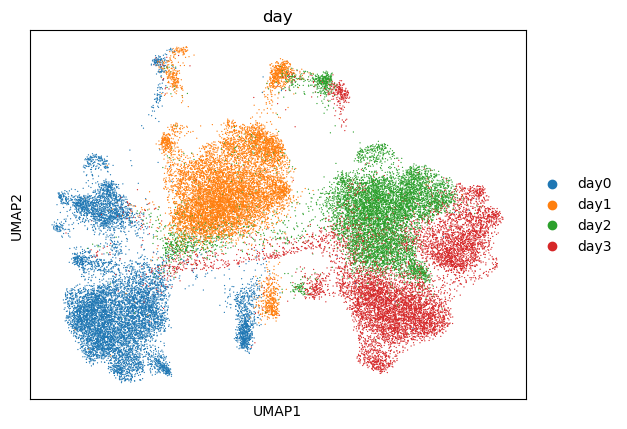

In [4]:
adata_copy = adata.copy()
sc.pp.highly_variable_genes(adata_copy)
adata_copy = adata_copy[:, adata_copy.var.highly_variable]
sc.pp.pca(adata_copy, n_comps=50)
# Compute the neighborhood graph
sc.pp.neighbors(adata_copy, n_neighbors=30, n_pcs=50)

# Run UMAP
sc.tl.umap(adata_copy)

# Plot UMAP
sc.pl.umap(adata_copy, color=['day'])  # Replace 'condition_column_name' with the relevant column name in your data
plt.show()


/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


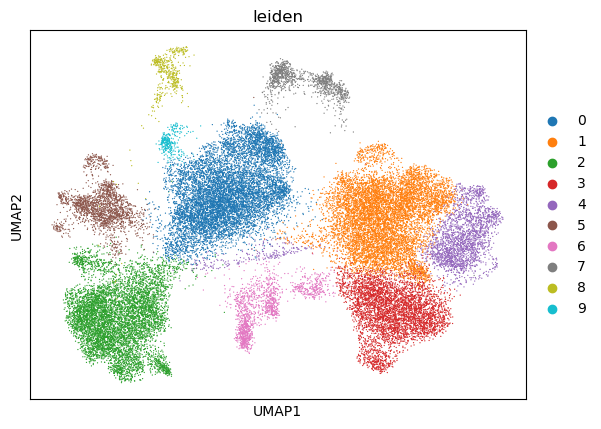

In [5]:
#seperate with dense group
sc.tl.leiden(adata_copy,resolution=0.4)
sc.pl.umap(adata_copy, color=['leiden'])  # Replace 'condition_column_name' with the relevant column name in your data
plt.show()


In [6]:
adata_day0 = adata[(adata_copy.obs['leiden']=='2')&(adata_copy.obs['day']=='day0')]
adata_day1 = adata[(adata_copy.obs['leiden']=='0')&(adata_copy.obs['day']=='day1')]
adata_day2 = adata[(adata_copy.obs['leiden']=='1')&(adata_copy.obs['day']=='day2')]
adata_day3 = adata[(adata_copy.obs['leiden']=='3')&(adata_copy.obs['day']=='day3')]


new_adata = sc.concat([adata_day0,adata_day1,adata_day2, adata_day3])
new_adata

AnnData object with n_obs × n_vars = 26225 × 11231
    obs: 'assigned', 'auxDir', 'cell_filter', 'cell_name', 'compatible_fragment_ratio', 'day', 'donor', 'expected_format', 'experiment', 'frag_dist_length', 'gc_bias_correct', 'is_cell_control', 'is_cell_control_bulk', 'is_cell_control_control', 'library_types', 'libType', 'log10_total_counts', 'log10_total_counts_endogenous', 'log10_total_counts_ERCC', 'log10_total_counts_feature_control', 'log10_total_counts_MT', 'log10_total_features', 'log10_total_features_endogenous', 'log10_total_features_ERCC', 'log10_total_features_feature_control', 'log10_total_features_MT', 'mapping_type', 'mates1', 'mates2', 'n_alt_reads', 'n_total_reads', 'num_assigned_fragments', 'num_bias_bins', 'num_bootstraps', 'num_compatible_fragments', 'num_consistent_mappings', 'num_inconsistent_mappings', 'num_libraries', 'num_mapped', 'num_processed', 'num_targets', 'nvars_used', 'pct_counts_endogenous', 'pct_counts_ERCC', 'pct_counts_feature_control', 'pct_counts

In [7]:
new_adata = adata

X = new_adata.X
# print(X)
# X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# print(X.size)
# X = X.astype(np.float32)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print(total)
print("min:", np.min(X))
print("max:", np.max(X))
print("mean:", np.mean(X))
print("below 0:", np.sum(X < 0))
print("below 0:", np.sum(X < 0)/total)
print("below 0.1:", np.sum(X < 0.1))
print("below 0.1:", np.sum(X < 0.1)/total)
print("below 0.2:", np.sum(X < 0.2))
print("below 0.2:", np.sum(X < 0.2)/total)

print("equals 0:", np.sum(X == 0))
print("equals 0:", np.sum(X == 0)/total)
print("below 18:", np.sum(X < 18))
print("below 18:", np.sum(X < 18)/total)
nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)

(36044, 11231)
404810164
404810164
min: 0.0
max: 16.7212129930232
mean: 2.8368180338881577
below 0: 0
below 0: 0.0
below 0.1: 110573929
below 0.1: 0.27315008078700315
below 0.2: 114246462
below 0.2: 0.28222231593967584
equals 0: 100773159
equals 0: 0.24893930034819975
below 18: 404810164
below 18: 1.0
nan: 0


In [ ]:
import scanpy as sc
import numpy as np

# Get unique groups
groups = new_adata.obs['day'].unique()
train_adata_list = []
val_adata_list = []
test_adata_list = []

# Random sampling 3000 cells per group and splitting
for group in groups:
    group_adata = new_adata[new_adata.obs['day'] == group]
    
    # Ensure there are at least 2000 cells in the group
    if group_adata.shape[0] < 2000:
        print(f"Group {group} has less than 3000 cells. Sampling {group_adata.shape[0]} cells.")
        sampled_adata = group_adata
    else:
        #sampled_indices = np.random.choice(group_adata.shape[0], 2000, replace=True)(author is wrong, will use same cells multiple times)
        sampled_indices = np.random.choice(group_adata.shape[0], 2000, replace=False)
        sampled_adata = group_adata[sampled_indices, :]

    # Shuffle the sampled data indices
    total_indices = np.arange(sampled_adata.shape[0])
    np.random.shuffle(total_indices)
    
    # Split into train, validation, and test datasets
    train_size = int(0.6 * sampled_adata.shape[0])
    val_size = int(0.1 * sampled_adata.shape[0])
    
    train_indices = total_indices[:train_size]
    val_indices = total_indices[train_size:train_size + val_size]
    test_indices = total_indices[train_size + val_size:]
    
    train_adata_list.append(sampled_adata[train_indices, :])
    val_adata_list.append(sampled_adata[val_indices, :])
    test_adata_list.append(sampled_adata[test_indices, :])

# Concatenate all subsampled data
train_adata = train_adata_list[0].concatenate(*train_adata_list[1:], batch_key="day", batch_categories=groups)
val_adata = val_adata_list[0].concatenate(*val_adata_list[1:], batch_key="day", batch_categories=groups)
test_adata = test_adata_list[0].concatenate(*test_adata_list[1:], batch_key="day", batch_categories=groups)
# train_adata = anndata.concat(
#     train_adata_list,
#     axis=0,
#     label="day",
#     keys=groups,
#     join="inner"
# )

# val_adata = anndata.concat(
#     val_adata_list,
#     axis=0,
#     label="day",
#     keys=groups,
#     join="inner"
# )

# test_adata = anndata.concat(
#     test_adata_list,
#     axis=0,
#     label="day",
#     keys=groups,
#     join="inner"
# )
# train_adata.obs_names_make_unique()
# val_adata.obs_names_make_unique()
# test_adata.obs_names_make_unique()
# Modify variable names if needed
train_adata.var_names = [i.split('_')[1] for i in train_adata.var_names]
val_adata.var_names = [i.split('_')[1] for i in val_adata.var_names]
test_adata.var_names = [i.split('_')[1] for i in test_adata.var_names]
print(train_adata)
train_adata.n_vars
train_adata.X = train_adata.X.astype(np.float64)
val_adata.X = val_adata.X.astype(np.float64)
test_adata.X = test_adata.X.astype(np.float64)

train_adata.write(f'diff_train_original.h5ad')
val_adata.write(f'diff_val_original.h5ad')
test_adata.write(f'diff_test_original.h5ad')


/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/anndata/_core/anndata.py:1763: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  warnings.warn(
/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/anndata/_core/anndata.py:1763: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  warnings.warn(
/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/anndata/_core/anndata.py:1763: FutureWarning: The AnnData.concatenate method is deprecated in favour of the anndata.concat function. Please use anndata.concat instead.

See the tutorial for concat at: https://anndata.readthedocs.io/en

AnnData object with n_obs × n_vars = 4800 × 11231
    obs: 'assigned', 'auxDir', 'cell_filter', 'cell_name', 'compatible_fragment_ratio', 'day', 'donor', 'expected_format', 'experiment', 'frag_dist_length', 'gc_bias_correct', 'is_cell_control', 'is_cell_control_bulk', 'is_cell_control_control', 'library_types', 'libType', 'log10_total_counts', 'log10_total_counts_endogenous', 'log10_total_counts_ERCC', 'log10_total_counts_feature_control', 'log10_total_counts_MT', 'log10_total_features', 'log10_total_features_endogenous', 'log10_total_features_ERCC', 'log10_total_features_feature_control', 'log10_total_features_MT', 'mapping_type', 'mates1', 'mates2', 'n_alt_reads', 'n_total_reads', 'num_assigned_fragments', 'num_bias_bins', 'num_bootstraps', 'num_compatible_fragments', 'num_consistent_mappings', 'num_inconsistent_mappings', 'num_libraries', 'num_mapped', 'num_processed', 'num_targets', 'nvars_used', 'pct_counts_endogenous', 'pct_counts_ERCC', 'pct_counts_feature_control', 'pct_counts_